# 2. Graphical monitoring and overfitting

Regression example: California Housing

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from keras.models import Sequential
from keras.layers import Input, Dense
from keras.datasets import california_housing

In [10]:
(inputs, targets), (x_test, y_test) = california_housing.load_data(version='small', 
                                        test_split=0.2)
print(inputs.shape, targets.shape)
print(x_test.shape, y_test.shape)

(480, 8) (480,)
(120, 8) (120,)


The dataset consist **600 samples** with **8 numerical input features** and the numerical **target variable**

20% (120 samples) is reserved for final testing of the model after the training has been completed.

This time, however, we divide the remaining 480 data samples further in two separate sets: a training set containing 380 samples and a **validation set of 100 samples**.


**Validation set (development set) serves 2 useful purposes:**
1. Monitoring during training,
2. Hyperparameter optimization

In [11]:
# Extract sets for training and validation
x_train = inputs[:380]
y_train = targets[:380]
x_val = inputs[380:]
y_val = targets[380:]

Next, standardize the input features by subtracting the mean and dividing by the standard deviation. 

Only the training set is used to estimate the mean and standard deviation in the dataset.

Then both the validation set and test set are also standardized using these values.

In [12]:

mean = x_train.mean(axis=0) # mean and standard deviation computed from training set only
std = x_train.std(axis=0)
x_train -= mean
x_train /= std
x_test -= mean
x_test /= std
x_val -= mean
x_val /= std
y_train /= 1e5
y_test /= 1e5
y_val /= 1e5

Preprocess is now done. 

Next constructing the neural network model for treating the regression problem for the above data can begin.

In [13]:
# define the model architecture
model = Sequential([
    Input(shape=(8,)),
    Dense(64, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1)
    ])

# configure the learning algorithm
model.compile(optimizer='adam',loss='mse',metrics=['mae'])

Next, train the model for 500 epochs, with the validation set extracted above.

In [14]:
history = model.fit(x_train, y_train, epochs=500, batch_size=32, validation_data=(x_val, y_val), verbose=0)


Text(0, 0.5, 'Loss')

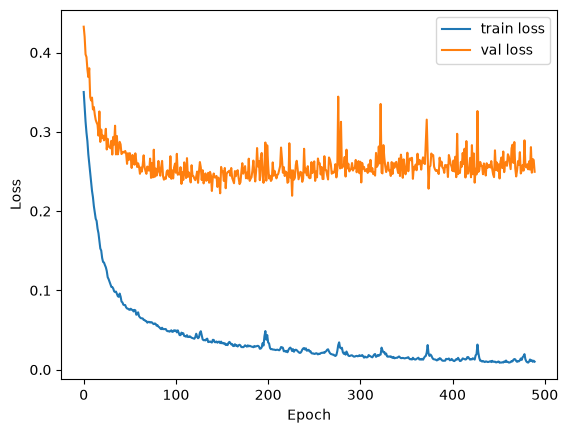

In [15]:

plt.plot(history.history['loss'][10:], label='train loss')
plt.plot(history.history['val_loss'][10:], label='val loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')

Text(0, 0.5, 'Mean absolute error (in 100000 $)')

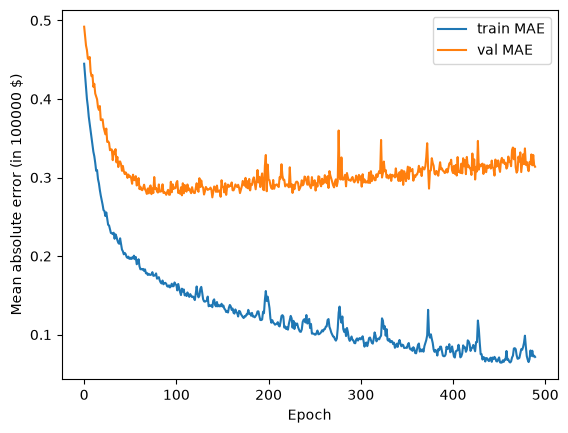

In [16]:
plt.plot(history.history['mae'][10:], label='train MAE')
plt.plot(history.history['val_mae'][10:], label='val MAE')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Mean absolute error (in 100000 $)')

In [17]:
x_train_full = np.concatenate((x_train, x_val), axis=0) # join train + val sets
y_train_full = np.concatenate((y_train, y_val), axis=0)

model = Sequential([
    Input(shape=(8,)),
    Dense(64, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1)
    ])

model.compile(optimizer='adam',loss='mse',metrics=['mae'])
model.fit(x_train_full, y_train_full, epochs=100, batch_size=32, verbose=0)

In [18]:
test_loss, test_mae = model.evaluate(x_test, y_test)
print(f'Test mean absolute error: {test_mae:.4f}')

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.2741 - mae: 0.3027
Test mean absolute error: 0.3027


In [19]:
from keras.losses import MeanAbsoluteError

y_pred_baseline = np.full_like(y_test, np.mean(y_train_full, axis=0))
mae_fn = MeanAbsoluteError()
mae_baseline = mae_fn(y_test, y_pred_baseline).numpy()
print(f'Mean baseline MAE: {mae_baseline:.4f}')

Mean baseline MAE: 0.8367
